# test getting dapi outline

In [1]:
import glob
import pandas as pd
import os
import pickle
import numpy as np

os.environ["PATH"] = os.path.expanduser("~/miniconda3/envs/fox_env24/bin") + ":" + os.environ["PATH"]
pd.options.mode.chained_assignment = None

# plotting packages
from bokeh.plotting import figure, show
from bokeh.io import export_svgs, output_notebook
from bokeh.models import ColumnDataSource, ColorBar, Span, Label, Range1d
from bokeh.transform import factor_cmap
from bokeh.models import Legend
from scipy.spatial import ConvexHull
from scipy.interpolate import splprep, splev

palette_hex = [
    "#73b9a5", "#a33f3e", "#2261b2", "#fea17b", "#c5aedf",
    "#d4af9e", "#fea8d4", "#7e5679", "#6ea9fd", "#bd8985",
    "#d36d54", "#e4d177", "#89aeb3", "#fec4a7", "#977d89",
    "#637fd0", "#93581c", "#4bcbfe", "#82e2dd", "#dea257",
    "#70715d", "#009aa5", "#c27869", "#a893c6", "#00eafa",
    "#a96296", "#769be0", "#aa5839", "#7dcab8", "#847ebb",
    "#f28679", "#286958", "#00838d", "#b9989c", "#de8a5c",
    "#e3c7fe", "#97792d", "#6d6cb7", "#8e586f", "#b9d08a",
    "#a8a6e3", "#c35653", "#50729f", "#70548b", "#575a99",
    "#b26270", "#a58d39", "#9cc2c8", "#c0af85", "#72999a",
    "#5ebafe", "#59d6ac", "#984649", "#1bb1ca", "#c99b89",
    "#8fe7a1", "#568972", "#6690e7", "#e5b76b", "#798258",
    "#9984aa", "#a9dfc8", "#567319", "#cd8b68", "#979bb7",
    "#b17981", "#bacde7", "#8c6d80", "#576424", "#cfbe91",
    "#b2abca", "#e6bcb3", "#9783cf", "#2e9096", "#bd6c41",
]

plot_hull = False
plot_other_chr = True

path = '/central/groups/mthomson/sgdata/CaiLab/michalp/Glioma_analysis/data/DNA_data'

# get all files
files = glob.glob(f"{path}/*assigned.csv")

# only keep 1 patient sample
patient_id = '2543'
files = [i for i in files if patient_id in i]

# load data
df_1 = pd.read_csv(files[0], low_memory=False)

# fix chromosomes
probe_df = pd.read_csv("/central/groups/CaiLab/personal/jjfox/DNA_seqFISH/human/24-12-19_human_genome_DNA_seqFISH_final_probes.csv")
df_unique = probe_df.drop_duplicates(subset='bin_name', keep='last')
chr_dict = dict(zip(df_unique['bin_name'], df_unique['chr']))

df_1["blockbin"] = (
    df_1["block_assigned"].str.replace("block_", "block", regex=False)
    + "_" +
    df_1["name"].str.replace("bin_", "bin", regex=False)
)
df_1['chromosome_true'] = df_1.blockbin.map(chr_dict)

# map chromosome arms
with open('chrom_arm_dict.pkl', 'rb') as f:
    chrom_arm_dict = pickle.load(f)

df_1['chrom_arm'] = df_1.blockbin.map(chrom_arm_dict)

# load cell type data
celltype_df = pd.read_csv('/resnick/groups/mthomson/ci2_data/CaiLab/gbm/dna_distance_data/V2_24_patients_Obj_mapped.csv', low_memory=False)
celltype_df.columns = [col.replace('.', '_') for col in celltype_df.columns]
celltype_df.rename(columns={'Unnamed: 0': 'cell_id'}, inplace=True)
gbm_cells = celltype_df.loc[celltype_df['ID'] == patient_id].copy()
gbm_cells['cell_id'] = gbm_cells['cell_id'].apply(lambda x: int(x.split('_')[0]))
gbm_cell_dict = dict(zip(gbm_cells['cell_id'], gbm_cells['predicted_celltype']))
df_1['predicted_celltype'] = df_1['matched_label'].map(gbm_cell_dict)
celltypes = df_1['predicted_celltype'].unique()


def compute_scale_bar(shared_x_range, shared_y_range, scale_bar_length=2, inset_frac=0.04):
    plot_x_min, plot_x_max = shared_x_range
    plot_y_min, plot_y_max = shared_y_range
    plot_x_span = plot_x_max - plot_x_min
    plot_y_span = plot_y_max - plot_y_min
    bar_inset_x = inset_frac * plot_x_span
    bar_inset_y = inset_frac * plot_y_span
    bar_x_end = plot_x_max - bar_inset_x
    bar_x_start = bar_x_end - scale_bar_length
    bar_y = plot_y_min + bar_inset_y
    return bar_x_start, bar_x_end, bar_y


def add_scale_bar(p, bar_x_start, bar_x_end, bar_y):
    p.line([bar_x_start, bar_x_end], [bar_y, bar_y], line_width=3, line_color="black")
    p.add_layout(Label(
        x=(bar_x_start + bar_x_end) / 2, y=bar_y,
        text="2 \u03bcm", text_align="center", text_baseline="bottom",
        text_color="black", text_font_size="10pt", y_offset=2))


def clean_axes(p):
    p.xaxis.axis_label = None
    p.yaxis.axis_label = None
    p.xgrid.grid_line_color = None
    p.ygrid.grid_line_color = None
    p.xaxis.major_label_text_font_size = "0pt"
    p.yaxis.major_label_text_font_size = "0pt"
    p.xaxis.major_tick_line_color = None
    p.xaxis.minor_tick_line_color = None
    p.yaxis.major_tick_line_color = None
    p.yaxis.minor_tick_line_color = None
    p.xaxis.axis_line_color = None
    p.yaxis.axis_line_color = None
    p.title.text_color = "white"


def sort_chromosomes(unique_chrs):
    unique_chrs = list(unique_chrs)
    unique_chrs.sort(key=lambda x: x.split('chr')[1])
    unique_chrs_num = unique_chrs[:-2]
    unique_chrs_num.sort(key=lambda x: int(x.split('chr')[1]))
    return unique_chrs_num + [unique_chrs[-2]] + [unique_chrs[-1]]


def compute_hull(df_cell, hull_gap=0.15):
    all_points = np.column_stack([df_cell['x'].values, df_cell['y'].values])
    hull = ConvexHull(all_points)
    hull_verts = all_points[hull.vertices]
    centroid = hull_verts.mean(axis=0)
    directions = hull_verts - centroid
    directions = directions / np.linalg.norm(directions, axis=1, keepdims=True)
    hull_verts_expanded = hull_verts + directions * hull_gap
    hull_verts_closed = np.vstack([hull_verts_expanded, hull_verts_expanded[0]])
    tck, u = splprep([hull_verts_closed[:, 0], hull_verts_closed[:, 1]], s=0, per=True, k=3)
    u_fine = np.linspace(0, 1, 300)
    hull_xs, hull_ys = splev(u_fine, tck)
    return list(hull_xs), list(hull_ys)


def compute_shared_range(df_cell, pad_frac=0.05):
    x_min, x_max = df_cell['x'].min(), df_cell['x'].max()
    y_min, y_max = df_cell['y'].min(), df_cell['y'].max()
    x_span = x_max - x_min
    y_span = y_max - y_min
    max_span = max(x_span, y_span)
    x_center = (x_min + x_max) / 2
    y_center = (y_min + y_max) / 2
    pad = pad_frac * max_span
    shared_x_range = (x_center - max_span/2 - pad, x_center + max_span/2 + pad)
    shared_y_range = (y_center - max_span/2 - pad, y_center + max_span/2 + pad)
    return shared_x_range, shared_y_range


def plot_cell(df_1, cell, label, out_dir, plot_hull=True, plot_other_chr=True, plot_size=670, scale_bar_length=2):
    df_cell = df_1.loc[df_1['matched_label'] == cell].copy()
    df_cell = df_cell[df_cell['chromosome_true'].notna()]

    shared_x_range, shared_y_range = compute_shared_range(df_cell)
    hull_xs, hull_ys = compute_hull(df_cell)
    bar_x_start, bar_x_end, bar_y = compute_scale_bar(shared_x_range, shared_y_range, scale_bar_length)

    unique_chrs = sort_chromosomes(df_cell['chromosome_true'].unique())
    palette = palette_hex[:len(unique_chrs)]

    # Plot 1: Chromosome scatter
    p = figure(title=f"Scatterplot by Chromosome Cell {cell}",
               width=plot_size, height=plot_size,
               background_fill_color="white",
               border_fill_color="white",
               outline_line_color=None,
               x_range=Range1d(start=shared_x_range[0], end=shared_x_range[1]),
               y_range=Range1d(start=shared_y_range[0], end=shared_y_range[1]))

    for chr_value, color in zip(unique_chrs, palette):
        chr_source = ColumnDataSource(df_cell[df_cell['chromosome_true'] == chr_value])
        p.scatter('x', 'y', source=chr_source, size=13, fill_alpha=0.8, color=color)

    if plot_hull:
        p.line(hull_xs, hull_ys, line_width=1.5, line_color="black", line_dash="dashed")
    
    clean_axes(p)
    add_scale_bar(p, bar_x_start, bar_x_end, bar_y)
    p.output_backend = "svg"
    export_svgs(p, filename=f"{out_dir}/{label}_chromosomes.svg")

    # Plot 2: chr arm scatter
    chrom_factors = ['p', 'q']
    color_mapper_arms = factor_cmap('chrom_arm', palette=[palette_hex[1], palette_hex[2]], factors=chrom_factors)

    for highlight_chr, plot_label in [('chr1', 'chr1'), ('chr19', 'chr19')]:
        df_cell_chr = df_cell.sort_values('chrom_arm', key=lambda x: x.map({'p': 0, 'q': 1}))

        p_arm = figure(title=f"Scatter Plot Colored by Chromosome Arm",
                       background_fill_color="white",
                       border_fill_color="white",
                       outline_line_color=None,
                       x_range=Range1d(start=shared_x_range[0], end=shared_x_range[1]),
                       y_range=Range1d(start=shared_y_range[0], end=shared_y_range[1]),
                       width=plot_size, height=plot_size)

        for chr_value in unique_chrs:
            if chr_value == highlight_chr:
                continue
            chr_source = ColumnDataSource(df_cell_chr[df_cell_chr['chromosome_true'] == chr_value])
            bg_color = '#CCCCCC' if plot_other_chr else '#FFFFFF'
            p_arm.scatter('x', 'y', source=chr_source, size=13, fill_alpha=0.8, color=bg_color)

        highlight_df = df_cell_chr[df_cell_chr['chromosome_true'] == highlight_chr]
        highlight_source = ColumnDataSource(highlight_df)
        color_mapper = factor_cmap('chrom_arm', palette=[palette_hex[1], palette_hex[2]], factors=chrom_factors)
        p_arm.scatter('x', 'y', source=highlight_source, size=13, fill_alpha=0.8, color=color_mapper)

        if plot_hull:
            p_arm.line(hull_xs, hull_ys, line_width=1.5, line_color="black", line_dash="dashed")

        clean_axes(p_arm)
        add_scale_bar(p_arm, bar_x_start, bar_x_end, bar_y)
        p_arm.output_backend = "svg"
        export_svgs(p_arm, filename=f"{out_dir}/{label}_{plot_label}.svg")

IndexError: list index out of range

In [2]:
json_file = '/home/jjfox/resnick_ci2_gbm_/V2_runs/analysis/25-04-14_2122_2543_4668_DNA_analysis/roi2_2543/segmentations/segmentation_nuclei.json'

In [3]:
import json

with open(json_file, "r") as f:
    data = json.load(f)

In [4]:
data

{'image': 'G:\\SPEC_Users\\JFox\\25-04-14_gbm_2122_2543_4668_DNA\\roi_2\\hyb_1_aligned.tiff',
 'image2': '',
 'channel': 3,
 'uuid': 'urn:uuid:8e8bad19-2b99-11f0-9255-10f60abc246b',
 'version': '0.9.0',
 'creator': 'Spatial Genomics, Inc.;sganalysis;0.9.0',
 'name': 'segmentation',
 'mtype': 'nuclei',
 'model_name': 'cyto2',
 'pretrained_model': '',
 'diameter': 10.0,
 'contrast': [[84, 8547]],
 'mode': 'NUCLEI',
 'flow_limit': 0.7,
 'cellprob': 0.3,
 'ensemble': True,
 'resample': True,
 'overlap': 0.1,
 'interp': False,
 'gpu': True,
 'block': 20000,
 'area_cut': 100,
 'expand_cells': 30,
 'wsip_thresh': 0,
 'wsip_blur': 7,
 'wsip_scale': 3,
 'num_channels': 4,
 'three_dim': False}

In [5]:
npy_file = '/home/jjfox/resnick_ci2_gbm_/V2_runs/analysis/25-04-14_2122_2543_4668_DNA_analysis/roi2_2543/segmentations/segmentation_nuclei.npz'
npy_data = np.load(npy_file)

In [6]:
npy_data

NpzFile '/home/jjfox/resnick_ci2_gbm_/V2_runs/analysis/25-04-14_2122_2543_4668_DNA_analysis/roi2_2543/segmentations/segmentation_nuclei.npz' with keys: uuid, max_label, areas, centroids

In [7]:
uuids = npy_data["uuid"]
max_label = npy_data["max_label"]
areas = npy_data["areas"]
centroids = npy_data["centroids"]

In [8]:
cell_id = 5  # example
area = areas[cell_id]
centroid = centroids[cell_id]

In [9]:
print(uuids.shape, areas.shape, centroids.shape)
print(max_label)

() (10592,) (10592, 2)
10592


In [10]:
centroid

array([  57, 3434], dtype=int32)

In [27]:
with open("segmentation_nuclei_2543.geojson", "r") as f:
    geojson = json.load(f)

In [28]:
print(geojson.keys())
print(len(geojson["features"]))
print(geojson["features"][0])

dict_keys(['type', 'features'])
25070
{'type': 'Feature', 'id': '1', 'geometry': {'type': 'Polygon', 'coordinates': [[[391, 4], [387, 15], [386, 40], [391, 52], [399, 61], [412, 67], [428, 71], [447, 73], [464, 73], [472, 70], [478, 65], [482, 54], [479, 28], [474, 12], [471, 6], [465, 0], [395, 0], [391, 4]]]}, 'properties': {'objectType': 'cell'}}


In [13]:
path = '/home/jjfox/resnick_ci2_gbm_/Data/DNA_data/'

# get all files
files = glob.glob(f"{path}/*assigned.csv")

# only keep 1 patient sample
patient_id = '2543'
files = [i for i in files if patient_id in i]

# load data
df_1 = pd.read_csv(files[0], low_memory=False)

In [14]:
df_1

,Unnamed: 0,x,y,z,name,matched_label,cell,block_assigned,distance,chromosome,sample
0,1,65.70,17.73,0.0,bin_1,1,120,block_32,0.110454,chr8,2543
1,2,63.96,14.49,0.0,bin_1,1,120,block_46,0.067082,chr12,2543
2,3,63.84,16.49,0.0,bin_1,1,120,block_24,0.064031,chr5,2543
3,4,65.70,18.14,0.0,bin_1,1,120,block_32,0.300167,chr8,2543
4,5,65.27,17.97,0.0,bin_1,1,120,block_22,0.072801,chr5,2543
...,...,...,...,...,...,...,...,...,...,...,...
63308083,63308084,3431.21,3765.18,4.2,MALAT1,24579,23753,NaN,0.000000,NaN,2543
63308084,63308085,3427.57,3763.05,4.2,MALAT1,24579,23753,NaN,0.000000,NaN,2543
63308085,63308086,3409.27,3955.11,4.2,MALAT1,25544,24662,NaN,0.000000,NaN,2543
63308086,63308087,3411.45,3954.02,4.2,MALAT1,25544,24662,NaN,0.000000,NaN,2543


In [15]:
df_1.loc[df_1['matched_label'] == 7763]

,Unnamed: 0,x,y,z,name,matched_label,cell,block_assigned,distance,chromosome,sample
36388926,36388927,2206.32,1196.78,0.0,bin_1,7763,7450,block_34,0.122066,chr8,2543
36388927,36388928,2207.94,1196.59,0.0,bin_1,7763,7450,block_14,0.031623,chr3,2543
36388928,36388929,2207.61,1196.61,0.0,bin_1,7763,7450,block_33,0.148661,chr8,2543
36388929,36388930,2207.33,1196.72,0.0,bin_1,7763,7450,block_33,0.212603,chr8,2543
36388930,36388931,2204.99,1197.26,0.0,bin_1,7763,7450,block_50,0.295296,chr14,2543
...,...,...,...,...,...,...,...,...,...,...,...
61980936,61980937,2209.27,1199.67,1.4,MALAT1,7763,7450,NaN,0.000000,NaN,2543
61980937,61980938,2208.46,1199.76,1.4,MALAT1,7763,7450,NaN,0.000000,NaN,2543
61980938,61980939,2210.50,1199.54,1.4,MALAT1,7763,7450,NaN,0.000000,NaN,2543
61980939,61980940,2210.05,1200.09,1.4,MALAT1,7763,7450,NaN,0.000000,NaN,2543


In [16]:
df_1.loc[df_1['matched_label'] == 2057]

,Unnamed: 0,x,y,z,name,matched_label,cell,block_assigned,distance,chromosome,sample
31230328,31230329,1252.26,290.98,0.0,bin_1,2057,2019,block_6,0.058310,chr1,2543
31230329,31230330,1252.94,290.63,0.0,bin_1,2057,2019,block_20,0.041231,chr4,2543
31230330,31230331,1259.35,291.56,0.0,bin_1,2057,2019,block_30,0.250200,chr7,2543
31230331,31230332,1252.14,291.48,0.0,bin_1,2057,2019,block_40,0.346554,chr10,2543
31230332,31230333,1251.30,291.75,0.0,bin_1,2057,2019,block_40,0.269258,chr10,2543
...,...,...,...,...,...,...,...,...,...,...,...
63207055,63207056,1255.76,295.29,3.5,MALAT1,2057,2019,NaN,0.000000,NaN,2543
63207056,63207057,1252.62,295.01,3.5,MALAT1,2057,2019,NaN,0.000000,NaN,2543
63207057,63207058,1255.02,294.43,3.5,MALAT1,2057,2019,NaN,0.000000,NaN,2543
63207058,63207059,1257.25,294.33,3.5,MALAT1,2057,2019,NaN,0.000000,NaN,2543


In [29]:
cell_2019 = next(f for f in geojson["features"] if f["id"] == "2019")
print(cell_2019)

{'type': 'Feature', 'id': '2019', 'geometry': {'type': 'Polygon', 'coordinates': [[[12120, 2804], [12100, 2793], [12097, 2790], [12091, 2793], [12072, 2793], [12067, 2791], [12059, 2791], [12048, 2795], [12037, 2804], [12028, 2820], [12011, 2843], [12007, 2853], [12009, 2862], [12019, 2873], [12045, 2892], [12065, 2898], [12075, 2898], [12088, 2893], [12101, 2882], [12113, 2862], [12138, 2832], [12132, 2817], [12120, 2804]]]}, 'properties': {'objectType': 'cell'}}


In [30]:
cell_2057 = next(f for f in geojson["features"] if f["id"] == "2057")
print(cell_2057)

{'type': 'Feature', 'id': '2057', 'geometry': {'type': 'Polygon', 'coordinates': [[[25427, 2849], [25407, 2851], [25388, 2858], [25373, 2866], [25364, 2868], [25370, 2892], [25384, 2930], [25398, 2957], [25407, 2968], [25420, 2951], [25431, 2940], [25452, 2929], [25458, 2923], [25461, 2918], [25464, 2907], [25463, 2896], [25458, 2887], [25458, 2881], [25451, 2869], [25450, 2862], [25440, 2857], [25437, 2853], [25427, 2849]]]}, 'properties': {'objectType': 'cell'}}


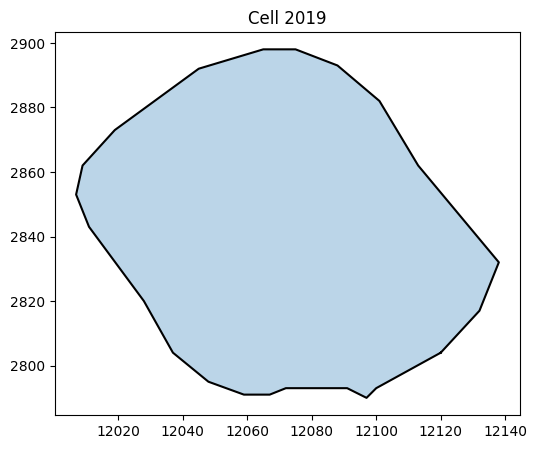

In [54]:
import matplotlib.pyplot as plt

coords = cell_2019["geometry"]["coordinates"][0]
xs, ys = zip(*coords)

plt.figure(figsize=(6, 6))
plt.fill(xs, ys, alpha=0.3)
plt.plot(xs, ys, "k-")
plt.gca().set_aspect("equal")
plt.title("Cell 2019")
plt.show()

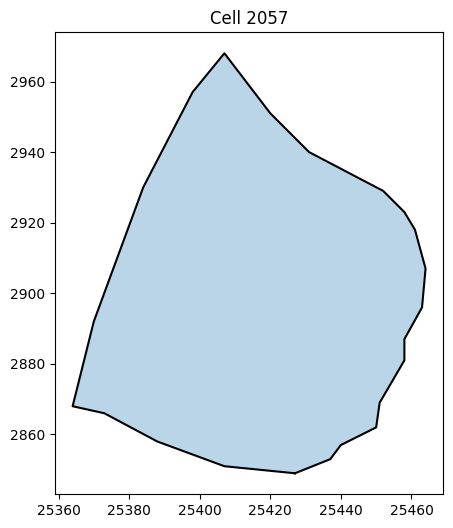

In [32]:
coords = cell_2057["geometry"]["coordinates"][0]
xs, ys = zip(*coords)

plt.figure(figsize=(6, 6))
plt.fill(xs, ys, alpha=0.3)
plt.plot(xs, ys, "k-")
plt.gca().set_aspect("equal")
plt.title("Cell 2057")
plt.show()

In [33]:
cell_7763 = next(f for f in geojson["features"] if f["id"] == "7763")

In [34]:
cell_7450 = next(f for f in geojson["features"] if f["id"] == "7450")

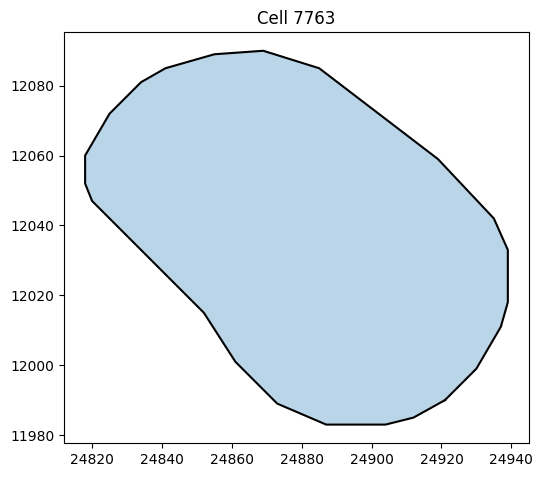

In [35]:
import matplotlib.pyplot as plt

coords = cell_7763["geometry"]["coordinates"][0]
xs, ys = zip(*coords)

plt.figure(figsize=(6, 6))
plt.fill(xs, ys, alpha=0.3)
plt.plot(xs, ys, "k-")
plt.gca().set_aspect("equal")
plt.title("Cell 7763")
plt.show()

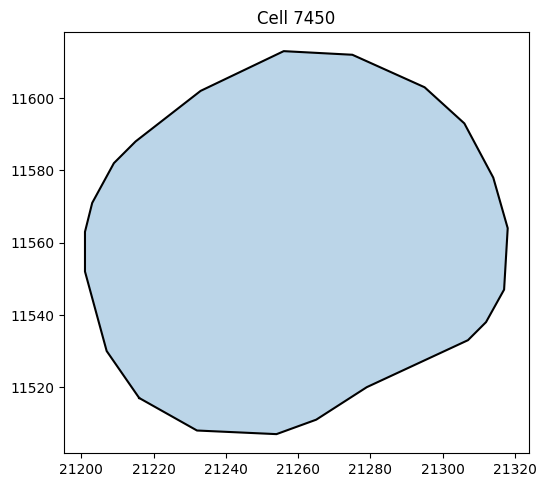

In [36]:
coords = cell_7450["geometry"]["coordinates"][0]
xs, ys = zip(*coords)

plt.figure(figsize=(6, 6))
plt.fill(xs, ys, alpha=0.3)
plt.plot(xs, ys, "k-")
plt.gca().set_aspect("equal")
plt.title("Cell 7450")
plt.show()

In [37]:
from bokeh.plotting import figure, show
from bokeh.io import export_svgs, output_notebook
output_notebook()

Loading BokehJS ...

In [40]:
# fix chromosomes
probe_df = pd.read_csv("/resnick/groups/CaiLab/jjfox/copied_from_central/DNA_seqFISH/human/24-12-19_human_genome_DNA_seqFISH_final_probes.csv")
df_unique = probe_df.drop_duplicates(subset='bin_name', keep='last')
chr_dict = dict(zip(df_unique['bin_name'], df_unique['chr']))

df_1["blockbin"] = (
    df_1["block_assigned"].str.replace("block_", "block", regex=False)
    + "_" +
    df_1["name"].str.replace("bin_", "bin", regex=False)
)
df_1['chromosome_true'] = df_1.blockbin.map(chr_dict)

# map chromosome arms
with open('chrom_arm_dict.pkl', 'rb') as f:
    chrom_arm_dict = pickle.load(f)

df_1['chrom_arm'] = df_1.blockbin.map(chrom_arm_dict)

# load cell type data
celltype_df = pd.read_csv('/resnick/groups/mthomson/ci2_data/CaiLab/gbm/dna_distance_data/V2_24_patients_Obj_mapped.csv', low_memory=False)
celltype_df.columns = [col.replace('.', '_') for col in celltype_df.columns]
celltype_df.rename(columns={'Unnamed: 0': 'cell_id'}, inplace=True)
gbm_cells = celltype_df.loc[celltype_df['ID'] == patient_id].copy()
gbm_cells['cell_id'] = gbm_cells['cell_id'].apply(lambda x: int(x.split('_')[0]))
gbm_cell_dict = dict(zip(gbm_cells['cell_id'], gbm_cells['predicted_celltype']))
df_1['predicted_celltype'] = df_1['matched_label'].map(gbm_cell_dict)
celltypes = df_1['predicted_celltype'].unique()


def compute_scale_bar(shared_x_range, shared_y_range, scale_bar_length=2, inset_frac=0.04):
    plot_x_min, plot_x_max = shared_x_range
    plot_y_min, plot_y_max = shared_y_range
    plot_x_span = plot_x_max - plot_x_min
    plot_y_span = plot_y_max - plot_y_min
    bar_inset_x = inset_frac * plot_x_span
    bar_inset_y = inset_frac * plot_y_span
    bar_x_end = plot_x_max - bar_inset_x
    bar_x_start = bar_x_end - scale_bar_length
    bar_y = plot_y_min + bar_inset_y
    return bar_x_start, bar_x_end, bar_y


def add_scale_bar(p, bar_x_start, bar_x_end, bar_y):
    p.line([bar_x_start, bar_x_end], [bar_y, bar_y], line_width=3, line_color="black")
    p.add_layout(Label(
        x=(bar_x_start + bar_x_end) / 2, y=bar_y,
        text="2 \u03bcm", text_align="center", text_baseline="bottom",
        text_color="black", text_font_size="10pt", y_offset=2))


def clean_axes(p):
    p.xaxis.axis_label = None
    p.yaxis.axis_label = None
    p.xgrid.grid_line_color = 'black'
    p.ygrid.grid_line_color = 'black'
    p.xaxis.major_label_text_font_size = "10pt"
    p.yaxis.major_label_text_font_size = "10pt"
    p.xaxis.major_tick_line_color = 'black'
    p.xaxis.minor_tick_line_color = 'black'
    p.yaxis.major_tick_line_color = 'black'
    p.yaxis.minor_tick_line_color = 'black'
    p.xaxis.axis_line_color = 'black'
    p.yaxis.axis_line_color = 'black'
    p.title.text_color = "white"


def sort_chromosomes(unique_chrs):
    unique_chrs = list(unique_chrs)
    unique_chrs.sort(key=lambda x: x.split('chr')[1])
    unique_chrs_num = unique_chrs[:-2]
    unique_chrs_num.sort(key=lambda x: int(x.split('chr')[1]))
    return unique_chrs_num + [unique_chrs[-2]] + [unique_chrs[-1]]


def compute_hull(df_cell, hull_gap=0.15):
    all_points = np.column_stack([df_cell['x'].values, df_cell['y'].values])
    hull = ConvexHull(all_points)
    hull_verts = all_points[hull.vertices]
    centroid = hull_verts.mean(axis=0)
    directions = hull_verts - centroid
    directions = directions / np.linalg.norm(directions, axis=1, keepdims=True)
    hull_verts_expanded = hull_verts + directions * hull_gap
    hull_verts_closed = np.vstack([hull_verts_expanded, hull_verts_expanded[0]])
    tck, u = splprep([hull_verts_closed[:, 0], hull_verts_closed[:, 1]], s=0, per=True, k=3)
    u_fine = np.linspace(0, 1, 300)
    hull_xs, hull_ys = splev(u_fine, tck)
    return list(hull_xs), list(hull_ys)


def compute_shared_range(df_cell, pad_frac=0.05):
    x_min, x_max = df_cell['x'].min(), df_cell['x'].max()
    y_min, y_max = df_cell['y'].min(), df_cell['y'].max()
    x_span = x_max - x_min
    y_span = y_max - y_min
    max_span = max(x_span, y_span)
    x_center = (x_min + x_max) / 2
    y_center = (y_min + y_max) / 2
    pad = pad_frac * max_span
    shared_x_range = (x_center - max_span/2 - pad, x_center + max_span/2 + pad)
    shared_y_range = (y_center - max_span/2 - pad, y_center + max_span/2 + pad)
    return shared_x_range, shared_y_range


def plot_cell(df_1, cell, label, out_dir, plot_hull=True, plot_other_chr=True, plot_size=670, scale_bar_length=2):
    df_cell = df_1.loc[df_1['matched_label'] == cell].copy()
    df_cell = df_cell[df_cell['chromosome_true'].notna()]

    shared_x_range, shared_y_range = compute_shared_range(df_cell)
    hull_xs, hull_ys = compute_hull(df_cell)
    bar_x_start, bar_x_end, bar_y = compute_scale_bar(shared_x_range, shared_y_range, scale_bar_length)

    unique_chrs = sort_chromosomes(df_cell['chromosome_true'].unique())
    palette = palette_hex[:len(unique_chrs)]

    # Plot 1: Chromosome scatter
    p = figure(title=f"Scatterplot by Chromosome Cell {cell}",
               width=plot_size, height=plot_size,
               background_fill_color="white",
               border_fill_color="white",
               outline_line_color=None,
               x_range=Range1d(start=shared_x_range[0], end=shared_x_range[1]),
               y_range=Range1d(start=shared_y_range[0], end=shared_y_range[1]))

    for chr_value, color in zip(unique_chrs, palette):
        chr_source = ColumnDataSource(df_cell[df_cell['chromosome_true'] == chr_value])
        p.scatter('x', 'y', source=chr_source, size=13, fill_alpha=0.8, color=color)

    if plot_hull:
        p.line(hull_xs, hull_ys, line_width=1.5, line_color="black", line_dash="dashed")
    
    clean_axes(p)
    add_scale_bar(p, bar_x_start, bar_x_end, bar_y)
    p.output_backend = "svg"
    #export_svgs(p, filename=f"{out_dir}/{label}_chromosomes.svg")
    show(p)

    # Plot 2: chr arm scatter
    chrom_factors = ['p', 'q']
    color_mapper_arms = factor_cmap('chrom_arm', palette=[palette_hex[1], palette_hex[2]], factors=chrom_factors)

    for highlight_chr, plot_label in [('chr1', 'chr1'), ('chr19', 'chr19')]:
        df_cell_chr = df_cell.sort_values('chrom_arm', key=lambda x: x.map({'p': 0, 'q': 1}))

        p_arm = figure(title=f"Scatter Plot Colored by Chromosome Arm",
                       background_fill_color="white",
                       border_fill_color="white",
                       outline_line_color=None,
                       x_range=Range1d(start=shared_x_range[0], end=shared_x_range[1]),
                       y_range=Range1d(start=shared_y_range[0], end=shared_y_range[1]),
                       width=plot_size, height=plot_size)

        for chr_value in unique_chrs:
            if chr_value == highlight_chr:
                continue
            chr_source = ColumnDataSource(df_cell_chr[df_cell_chr['chromosome_true'] == chr_value])
            bg_color = '#CCCCCC' if plot_other_chr else '#FFFFFF'
            p_arm.scatter('x', 'y', source=chr_source, size=13, fill_alpha=0.8, color=bg_color)

        highlight_df = df_cell_chr[df_cell_chr['chromosome_true'] == highlight_chr]
        highlight_source = ColumnDataSource(highlight_df)
        color_mapper = factor_cmap('chrom_arm', palette=[palette_hex[1], palette_hex[2]], factors=chrom_factors)
        p_arm.scatter('x', 'y', source=highlight_source, size=13, fill_alpha=0.8, color=color_mapper)

        if plot_hull:
            p_arm.line(hull_xs, hull_ys, line_width=1.5, line_color="black", line_dash="dashed")

        clean_axes(p_arm)
        add_scale_bar(p_arm, bar_x_start, bar_x_end, bar_y)
        p_arm.output_backend = "svg"
        #export_svgs(p_arm, filename=f"{out_dir}/{label}_{plot_label}.svg")
        show(p_arm)


out_dir = "../../../figures/Figure_2/Figure_2B"
os.makedirs(out_dir, exist_ok=True)

#plot_cell(df_1, cell=7763, label="2543_OPC",        out_dir=out_dir, plot_hull=plot_hull, plot_other_chr=plot_other_chr)
plot_cell(df_1, cell=2057, label="2543_oligNormal", out_dir=out_dir, plot_hull=plot_hull, plot_other_chr=plot_other_chr)

In [41]:
def clean_axes(p):
    p.xaxis.axis_label = None
    p.yaxis.axis_label = None
    p.xgrid.grid_line_color = 'black'
    p.ygrid.grid_line_color = 'black'
    p.xaxis.major_label_text_font_size = "10pt"
    p.yaxis.major_label_text_font_size = "10pt"
    p.xaxis.major_tick_line_color = 'black'
    p.xaxis.minor_tick_line_color = 'black'
    p.yaxis.major_tick_line_color = 'black'
    p.yaxis.minor_tick_line_color = 'black'
    p.xaxis.axis_line_color = 'black'
    p.yaxis.axis_line_color = 'black'
    p.title.text_color = "white"

plot_cell(df_1, cell=2057, label="2543_oligNormal", out_dir=out_dir, plot_hull=plot_hull, plot_other_chr=plot_other_chr)

In [62]:
plot_hull = True


def plot_cell(df_1, cell, label, out_dir, plot_hull=True, plot_other_chr=True, plot_size=670, scale_bar_length=2):
    df_cell = df_1.loc[df_1['matched_label'] == cell].copy()
    df_cell = df_cell[df_cell['chromosome_true'].notna()]

    shared_x_range, shared_y_range = compute_shared_range(df_cell)
    hull_xs, hull_ys = compute_hull(df_cell)
    bar_x_start, bar_x_end, bar_y = compute_scale_bar(shared_x_range, shared_y_range, scale_bar_length)

    unique_chrs = sort_chromosomes(df_cell['chromosome_true'].unique())
    palette = palette_hex[:len(unique_chrs)]

    # Plot 1: Chromosome scatter
    p = figure(title=f"Scatterplot by Chromosome Cell {cell}",
               width=plot_size, height=plot_size,
               background_fill_color="white",
               border_fill_color="white",
               outline_line_color=None,
               x_range=Range1d(start=shared_x_range[0], end=shared_x_range[1]),
               y_range=Range1d(start=shared_y_range[0], end=shared_y_range[1]))

    for chr_value, color in zip(unique_chrs, palette):
        chr_source = ColumnDataSource(df_cell[df_cell['chromosome_true'] == chr_value])
        p.scatter('x', 'y', source=chr_source, size=13, fill_alpha=0.8, color=color)

    if plot_hull:
        p.line(hull_xs, hull_ys, line_width=1.5, line_color="black", line_dash="dashed")
    
    clean_axes(p)
    add_scale_bar(p, bar_x_start, bar_x_end, bar_y)
    p.output_backend = "svg"
    #export_svgs(p, filename=f"{out_dir}/{label}_chromosomes.svg")
    show(p)

    # Plot 2: chr arm scatter
    chrom_factors = ['p', 'q']
    color_mapper_arms = factor_cmap('chrom_arm', palette=[palette_hex[1], palette_hex[2]], factors=chrom_factors)

    for highlight_chr, plot_label in [('chr1', 'chr1'), ('chr19', 'chr19')]:
        df_cell_chr = df_cell.sort_values('chrom_arm', key=lambda x: x.map({'p': 0, 'q': 1}))

        p_arm = figure(title=f"Scatter Plot Colored by Chromosome Arm",
                       background_fill_color="white",
                       border_fill_color="white",
                       outline_line_color=None,
                       x_range=Range1d(start=shared_x_range[0], end=shared_x_range[1]),
                       y_range=Range1d(start=shared_y_range[0], end=shared_y_range[1]),
                       width=plot_size, height=plot_size)

        for chr_value in unique_chrs:
            if chr_value == highlight_chr:
                continue
            chr_source = ColumnDataSource(df_cell_chr[df_cell_chr['chromosome_true'] == chr_value])
            bg_color = '#CCCCCC' if plot_other_chr else '#FFFFFF'
            p_arm.scatter('x', 'y', source=chr_source, size=13, fill_alpha=0.8, color=bg_color)

        highlight_df = df_cell_chr[df_cell_chr['chromosome_true'] == highlight_chr]
        highlight_source = ColumnDataSource(highlight_df)
        color_mapper = factor_cmap('chrom_arm', palette=[palette_hex[1], palette_hex[2]], factors=chrom_factors)
        p_arm.scatter('x', 'y', source=highlight_source, size=13, fill_alpha=0.8, color=color_mapper)

        if plot_hull:
            p_arm.line(xs_conv, ys_conv, line_width=1.5, line_color="black", line_dash="dashed")

        clean_axes(p_arm)
        add_scale_bar(p_arm, bar_x_start, bar_x_end, bar_y)
        p_arm.output_backend = "svg"
        #export_svgs(p_arm, filename=f"{out_dir}/{label}_{plot_label}.svg")
        show(p_arm)


out_dir = "../../../figures/Figure_2/Figure_2B"
os.makedirs(out_dir, exist_ok=True)

#plot_cell(df_1, cell=7763, label="2543_OPC",        out_dir=out_dir, plot_hull=plot_hull, plot_other_chr=plot_other_chr)
plot_cell(df_1, cell=2057, label="2543_oligNormal", out_dir=out_dir, plot_hull=plot_hull, plot_other_chr=plot_other_chr)

In [61]:
xs_conv = tuple(x / 9.62 for x in xs)
ys_conv = tuple(y / 9.62 for y in ys)

In [64]:
df_1.loc[df_1['matched_label'] == 2057]['cell'].iloc[0]

2019

# pulling the masks

In [74]:
# get DNA cell id
dna_cell_id = df_1.loc[df_1['matched_label'] == 2057]['cell'].iloc[0]

In [65]:
analysis_dir = '/resnick/groups/mthomson/ci2_data/CaiLab/gbm/V2_runs/analysis'

In [66]:
files = glob.glob(analysis_dir + f"/*{patient_id}*/roi*{patient_id}/segmentations/segmentation_nuclei.zip")

In [70]:
geofile = files[-1]

In [71]:
import zipfile
import json
import tempfile
import os

def load_geojson_from_zip(zip_path):
    with tempfile.TemporaryDirectory() as tmpdir:
        with zipfile.ZipFile(zip_path, "r") as z:
            geojson_files = [f for f in z.namelist() if f.endswith(".geojson")]
            if not geojson_files:
                raise FileNotFoundError("No .geojson file found in the archive.")
            z.extract(geojson_files[0], tmpdir)
            with open(os.path.join(tmpdir, geojson_files[0])) as f:
                data = json.load(f)
    return data

geojson = load_geojson_from_zip(geofile)
print(type(geojson))
print(len(geojson["features"]))

<class 'dict'>
25070


In [77]:
cell_2019 = next(f for f in geojson["features"] if f["id"] == str(dna_cell_id))
print(cell_2019)

{'type': 'Feature', 'id': '2019', 'geometry': {'type': 'Polygon', 'coordinates': [[[12120, 2804], [12100, 2793], [12097, 2790], [12091, 2793], [12072, 2793], [12067, 2791], [12059, 2791], [12048, 2795], [12037, 2804], [12028, 2820], [12011, 2843], [12007, 2853], [12009, 2862], [12019, 2873], [12045, 2892], [12065, 2898], [12075, 2898], [12088, 2893], [12101, 2882], [12113, 2862], [12138, 2832], [12132, 2817], [12120, 2804]]]}, 'properties': {'objectType': 'cell'}}
